<a href="https://colab.research.google.com/github/uncertain-uncertainity/Learning/blob/main/customer_churn_prediction.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Customer Churn Prediction

XGBoost churn classifier on the IBM Telco Customer Churn dataset (7,043 customers). The notebook covers EDA, a preprocessing pipeline, class imbalance handling, K-Fold benchmarking of Logistic Regression, Random Forest and XGBoost, GridSearchCV tuning of XGBoost, and evaluation on a 33% hold-out set.

In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (ConfusionMatrixDisplay, RocCurveDisplay, classification_report,
                             f1_score, precision_score, recall_score, roc_auc_score)
from sklearn.model_selection import GridSearchCV, StratifiedKFold, cross_validate, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from xgboost import XGBClassifier

RANDOM_STATE = 42

## 1. Data

In [5]:
df = pd.read_csv('/content/WA_Fn-UseC_-Telco-Customer-Churn.csv')
print(df.shape)
df.head()

(7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


## 2. Cleaning

`customerID` is an identifier and is dropped. `TotalCharges` is stored as text and is blank for the customers with `tenure` 0 (no billing yet), so it is converted to numeric and set to 0 for them. The target `Churn` is encoded as 1 for Yes and 0 for No.

In [7]:
df = df.drop(columns='customerID')
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce').fillna(0)
df['Churn'] = df['Churn'].map({'No': 0, 'Yes': 1})

print(df.shape)
print(df.isna().sum().sum(), 'missing values')
df['Churn'].value_counts(normalize=True).round(3)

(7043, 20)
0 missing values


,proportion
Churn,
0,0.735
1,0.265


## 3. Exploratory data analysis

### Class balance and churn by customer segment

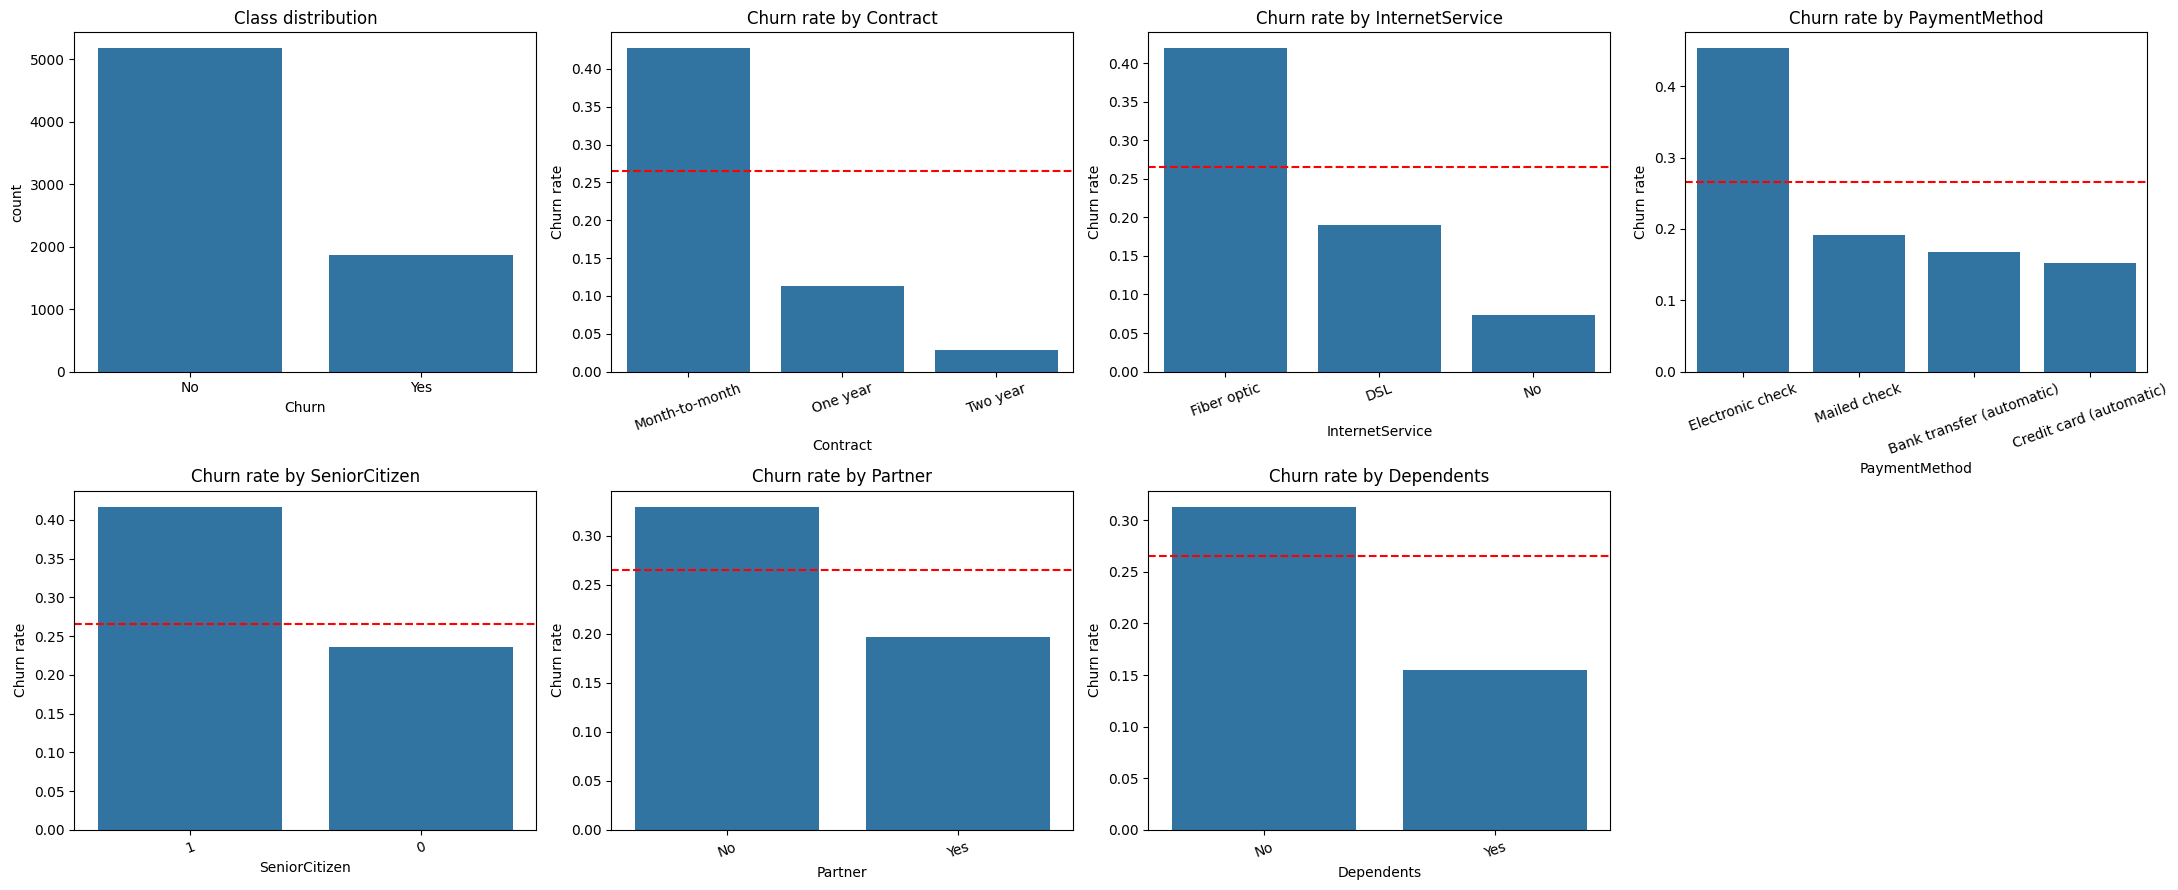

In [8]:
segments = ['Contract', 'InternetService', 'PaymentMethod', 'SeniorCitizen', 'Partner', 'Dependents']

fig, axes = plt.subplots(2, 4, figsize=(22, 9))
sns.countplot(x=df['Churn'].map({0: 'No', 1: 'Yes'}), ax=axes[0, 0])
axes[0, 0].set_title('Class distribution')
axes[0, 0].set_xlabel('Churn')

for ax, col in zip(axes.flatten()[1:], segments):
    rate = df.groupby(col)['Churn'].mean().sort_values(ascending=False)
    sns.barplot(x=rate.index.astype(str), y=rate.values, ax=ax)
    ax.axhline(df['Churn'].mean(), color='red', linestyle='--', label='Overall')
    ax.set_title(f'Churn rate by {col}')
    ax.set_ylabel('Churn rate')
    ax.tick_params(axis='x', rotation=20)
axes[1, 3].set_visible(False)
plt.tight_layout()
plt.show()

### Cohort analysis

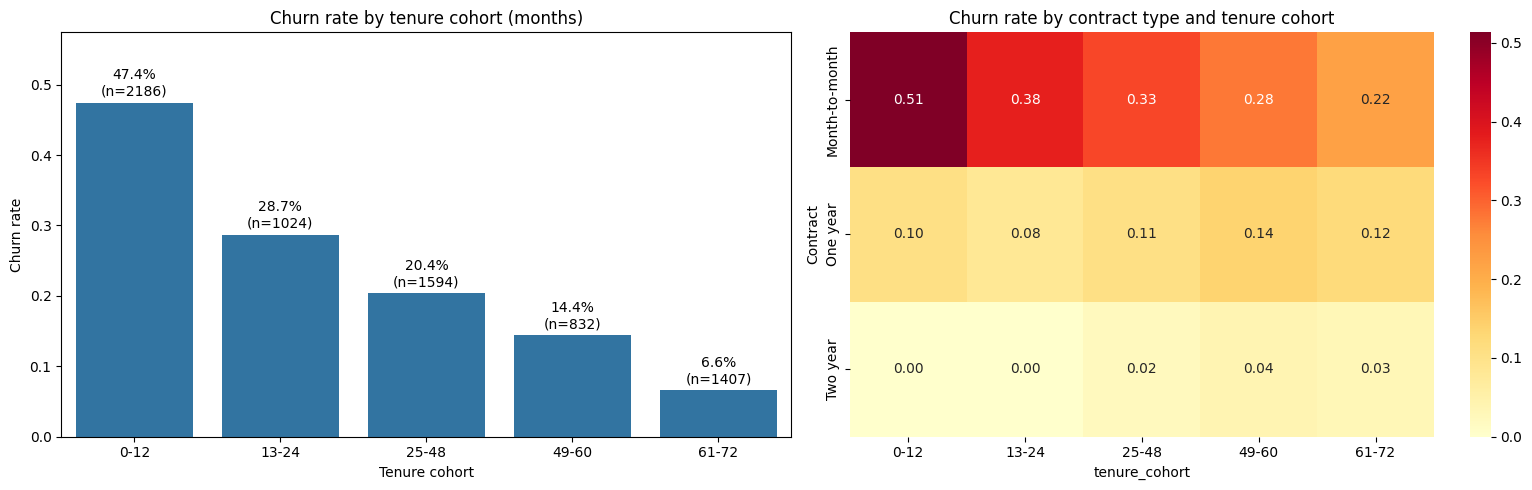

In [9]:
df['tenure_cohort'] = pd.cut(df['tenure'], bins=[-1, 12, 24, 48, 60, 72],
                             labels=['0-12', '13-24', '25-48', '49-60', '61-72'])

cohort_rate = df.groupby('tenure_cohort', observed=True)['Churn'].mean()
cohort_size = df.groupby('tenure_cohort', observed=True).size()

fig, axes = plt.subplots(1, 2, figsize=(16, 5))
sns.barplot(x=cohort_rate.index.astype(str), y=cohort_rate.values, ax=axes[0])
for i, (rate, size) in enumerate(zip(cohort_rate, cohort_size)):
    axes[0].text(i, rate + 0.01, f'{rate:.1%}\n(n={size})', ha='center')
axes[0].set_ylim(0, cohort_rate.max() + 0.1)
axes[0].set_title('Churn rate by tenure cohort (months)')
axes[0].set_xlabel('Tenure cohort')
axes[0].set_ylabel('Churn rate')

contract_cohort = df.pivot_table(index='Contract', columns='tenure_cohort', values='Churn',
                                 aggfunc='mean', observed=True)
sns.heatmap(contract_cohort, annot=True, fmt='.2f', cmap='YlOrRd', ax=axes[1])
axes[1].set_title('Churn rate by contract type and tenure cohort')
plt.tight_layout()
plt.show()

### Heatmaps

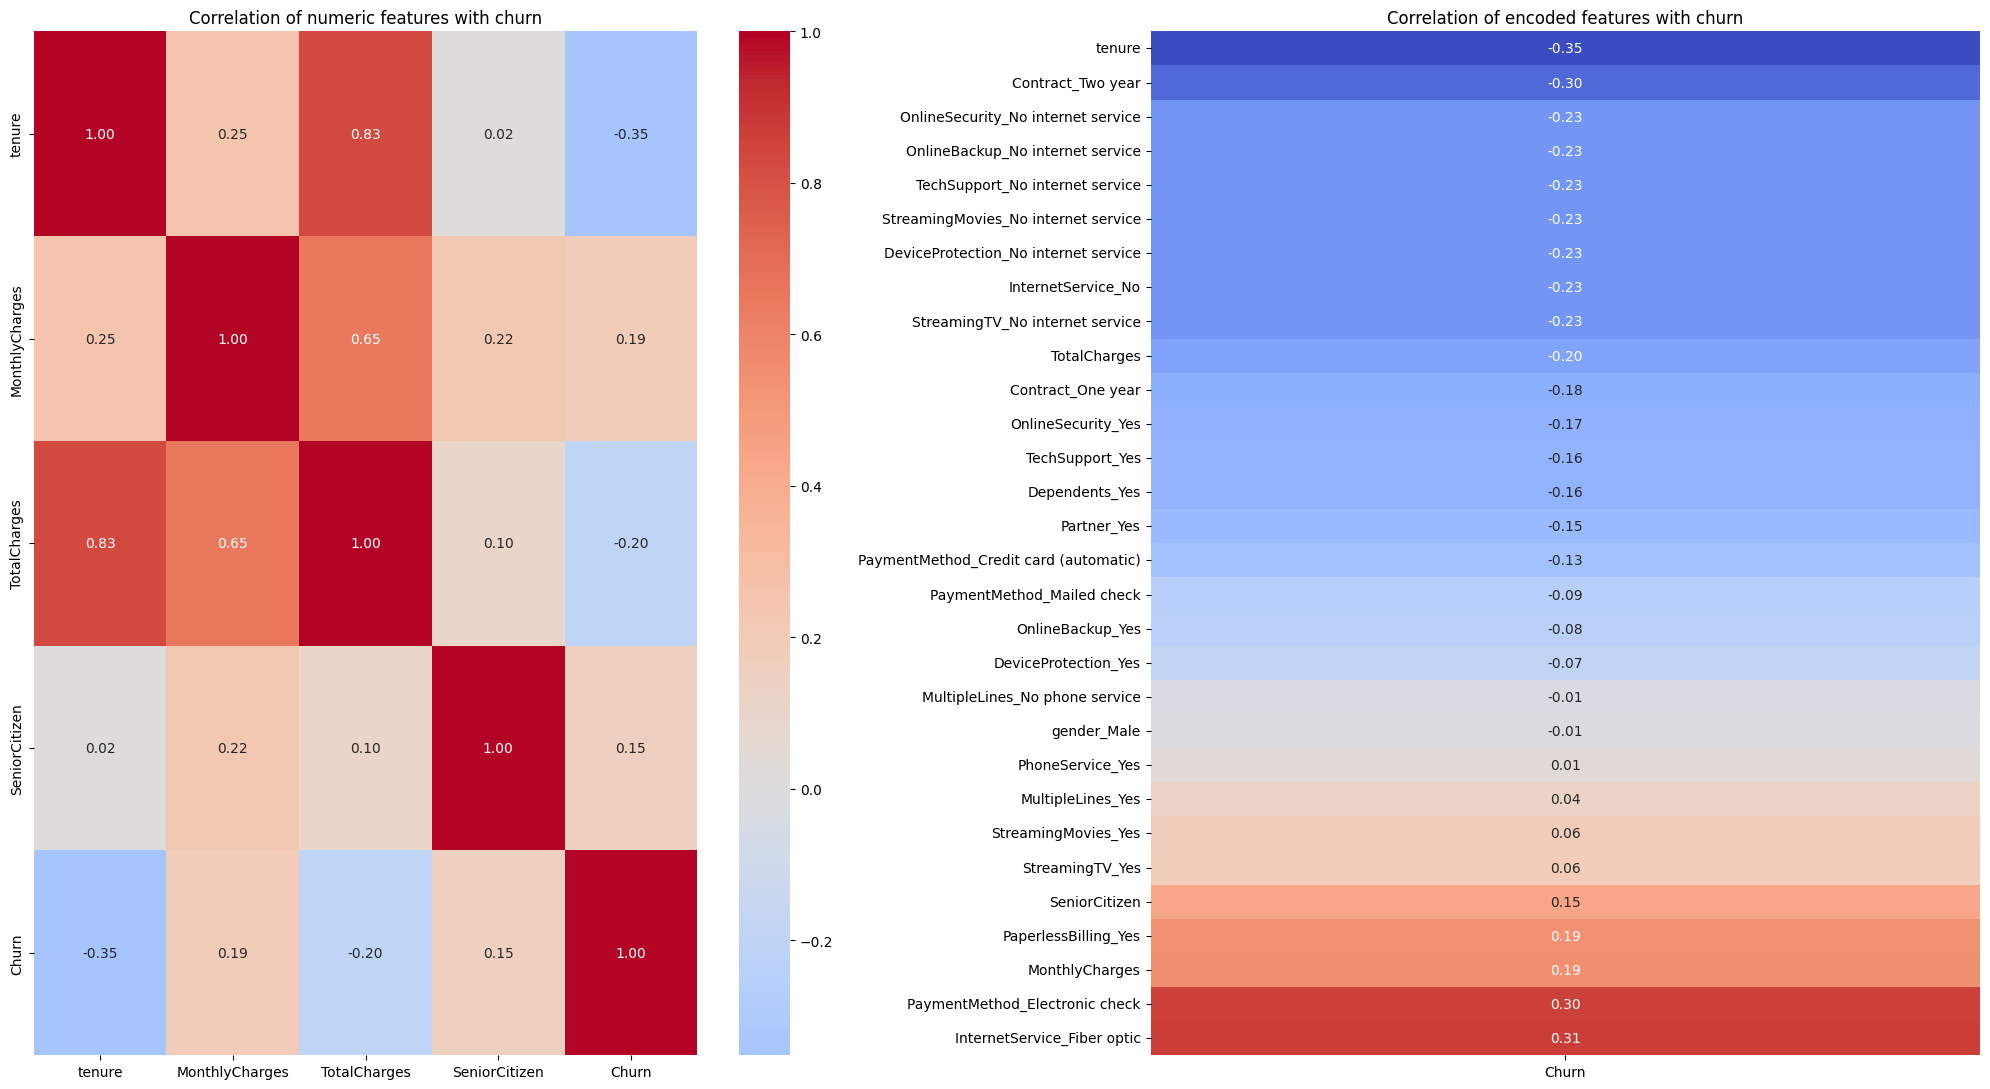

In [10]:
num_cols = ['tenure', 'MonthlyCharges', 'TotalCharges']
encoded = pd.get_dummies(df.drop(columns='tenure_cohort'), drop_first=True).astype(float)
churn_corr = encoded.corr()['Churn'].drop('Churn').sort_values()

fig, axes = plt.subplots(1, 2, figsize=(20, 11), gridspec_kw={'width_ratios': [1, 1]})
sns.heatmap(df[num_cols + ['SeniorCitizen', 'Churn']].corr(), annot=True, fmt='.2f',
            cmap='coolwarm', center=0, ax=axes[0])
axes[0].set_title('Correlation of numeric features with churn')

sns.heatmap(churn_corr.to_frame('Churn'), annot=True, fmt='.2f', cmap='coolwarm', center=0,
            cbar=False, ax=axes[1])
axes[1].set_title('Correlation of encoded features with churn')
plt.tight_layout()
plt.show()

### Pair plots

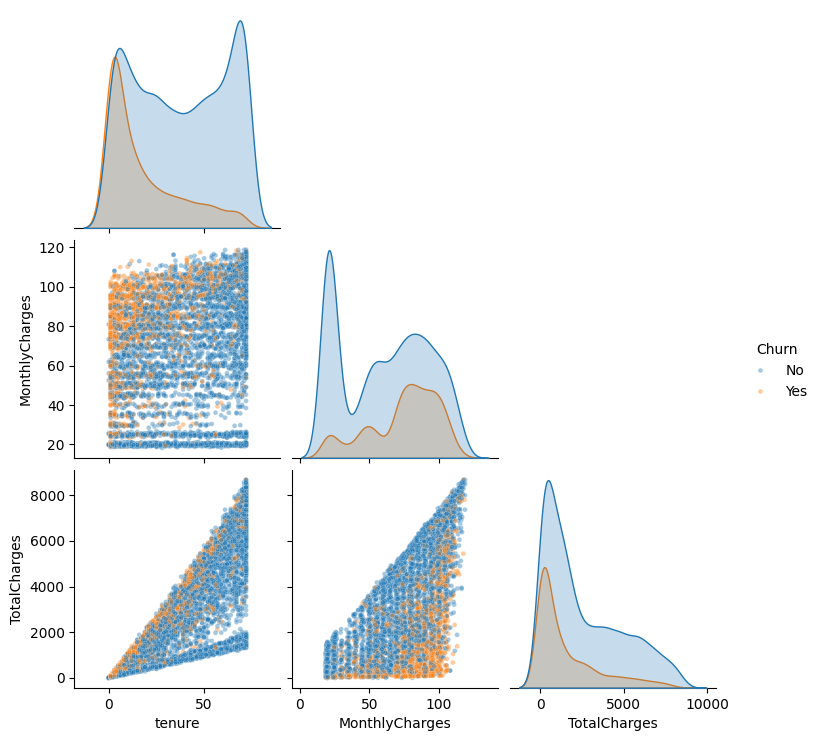

In [11]:
pair_df = df[num_cols + ['Churn']].assign(Churn=df['Churn'].map({0: 'No', 1: 'Yes'}))
sns.pairplot(pair_df, hue='Churn', corner=True, plot_kws={'alpha': 0.4, 's': 12})
plt.show()

## 4. Train/test split

33% of the data is held out for the final evaluation. The split is stratified so that both sets keep the same churn rate.

In [12]:
X = df.drop(columns=['Churn', 'tenure_cohort'])
y = df['Churn']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.33, stratify=y, random_state=RANDOM_STATE)

print(X_train.shape, X_test.shape)
print('Churn rate train / test:', round(y_train.mean(), 3), '/', round(y_test.mean(), 3))

(4718, 19) (2325, 19)
Churn rate train / test: 0.265 / 0.265


## 5. Preprocessing pipeline and class imbalance

Numeric features are standardised and categorical features are one-hot encoded inside a `ColumnTransformer`, so every transformation is fitted on training data only. Churners are about a quarter of the customers, so Logistic Regression and Random Forest use `class_weight='balanced'` and XGBoost uses `scale_pos_weight` (negatives divided by positives in the training set). Models are compared on ROC-AUC, precision, recall and F1 rather than accuracy.

In [13]:
cat_cols = X_train.select_dtypes(exclude='number').columns.tolist()

preprocessor = ColumnTransformer([
    ('num', StandardScaler(), num_cols),
    ('cat', OneHotEncoder(drop='if_binary', handle_unknown='ignore'), cat_cols),
], remainder='passthrough')

scale_pos_weight = (y_train == 0).sum() / (y_train == 1).sum()
print('scale_pos_weight:', round(scale_pos_weight, 3))


def build(model):
    return Pipeline([('prep', preprocessor), ('model', model)])


models = {
    'Logistic Regression': build(LogisticRegression(max_iter=1000, class_weight='balanced')),
    'Random Forest': build(RandomForestClassifier(n_estimators=300, class_weight='balanced',
                                                  random_state=RANDOM_STATE, n_jobs=-1)),
    'XGBoost': build(XGBClassifier(scale_pos_weight=scale_pos_weight, eval_metric='logloss',
                                   random_state=RANDOM_STATE, n_jobs=-1)),
}

scale_pos_weight: 2.768


## 6. Benchmarking with K-Fold cross-validation

The three models are compared with stratified 5-fold cross-validation on the training set.

In [14]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
scoring = {'roc_auc': 'roc_auc', 'precision': 'precision', 'recall': 'recall', 'f1': 'f1'}

rows, cv_auc = [], {}
for name, pipe in models.items():
    res = cross_validate(pipe, X_train, y_train, cv=cv, scoring=scoring)
    cv_auc[name] = res['test_roc_auc'].mean()
    rows.append({
        'Model': name,
        'ROC-AUC': res['test_roc_auc'].mean(),
        'ROC-AUC std': res['test_roc_auc'].std(),
        'Precision': res['test_precision'].mean(),
        'Recall': res['test_recall'].mean(),
        'F1-score': res['test_f1'].mean(),
    })

benchmark = pd.DataFrame(rows).set_index('Model').round(4)
benchmark

,ROC-AUC,ROC-AUC std,Precision,Recall,F1-score
Model,,,,,
Logistic Regression,0.8456,0.0119,0.5124,0.7980,0.6240
Random Forest,0.8283,0.0151,0.6521,0.4809,0.5532
XGBoost,0.8204,0.0110,0.5489,0.6334,0.5880


## 7. XGBoost hyperparameter tuning

GridSearchCV tunes XGBoost with the same stratified 5-fold split, scored on validation ROC-AUC.

In [15]:
param_grid = {
    'model__n_estimators': [200, 400],
    'model__max_depth': [3, 4, 5],
    'model__learning_rate': [0.03, 0.05, 0.1],
    'model__subsample': [0.8, 1.0],
    'model__colsample_bytree': [0.8, 1.0],
}

xgb_search = GridSearchCV(
    build(XGBClassifier(scale_pos_weight=scale_pos_weight, eval_metric='logloss',
                        random_state=RANDOM_STATE, n_jobs=1)),
    param_grid, scoring='roc_auc', cv=cv, n_jobs=-1)
xgb_search.fit(X_train, y_train)

print('Best validation ROC-AUC:', round(xgb_search.best_score_, 4))
print(xgb_search.best_params_)

Best validation ROC-AUC: 0.8497
{'model__colsample_bytree': 1.0, 'model__learning_rate': 0.03, 'model__max_depth': 3, 'model__n_estimators': 200, 'model__subsample': 0.8}


In [16]:
pd.DataFrame(xgb_search.cv_results_).sort_values('rank_test_score').head(5)[
    ['params', 'mean_test_score', 'std_test_score']].round(4)

,params,mean_test_score,std_test_score
36,"{'model__colsample_bytree': 1.0, 'model__learn...",0.8497,0.0121
0,"{'model__colsample_bytree': 0.8, 'model__learn...",0.8495,0.0124
12,"{'model__colsample_bytree': 0.8, 'model__learn...",0.8490,0.0121
1,"{'model__colsample_bytree': 0.8, 'model__learn...",0.8488,0.0121
48,"{'model__colsample_bytree': 1.0, 'model__learn...",0.8487,0.0129


## 8. Model selection

The model with the highest validation ROC-AUC across the benchmark and the tuned XGBoost is selected. The hold-out set is not used for this choice.

In [17]:
models['XGBoost (tuned)'] = xgb_search.best_estimator_
cv_auc['XGBoost (tuned)'] = xgb_search.best_score_

selection = pd.Series(cv_auc, name='Validation ROC-AUC').round(4).sort_values(ascending=False)
best_name = selection.index[0]
final_model = models[best_name].fit(X_train, y_train)

print(f'Selected model: {best_name}')
selection.to_frame()

Selected model: XGBoost (tuned)


,Validation ROC-AUC
XGBoost (tuned),0.8497
Logistic Regression,0.8456
Random Forest,0.8283
XGBoost,0.8204


## 9. Hold-out evaluation

The selected model is evaluated once on the 33% hold-out set.

In [18]:
y_score = final_model.predict_proba(X_test)[:, 1]
y_pred = final_model.predict(X_test)

holdout = pd.Series({
    'ROC-AUC': roc_auc_score(y_test, y_score),
    'Precision': precision_score(y_test, y_pred),
    'Recall': recall_score(y_test, y_pred),
    'F1-score': f1_score(y_test, y_pred),
}, name=best_name).round(4)

print(classification_report(y_test, y_pred, target_names=['No churn', 'Churn']))
holdout.to_frame()

              precision    recall  f1-score   support

    No churn       0.92      0.73      0.81      1708
       Churn       0.52      0.82      0.64       617

    accuracy                           0.75      2325
   macro avg       0.72      0.77      0.72      2325
weighted avg       0.81      0.75      0.77      2325



,XGBoost (tuned)
ROC-AUC,0.8467
Precision,0.5212
Recall,0.8152
F1-score,0.6359


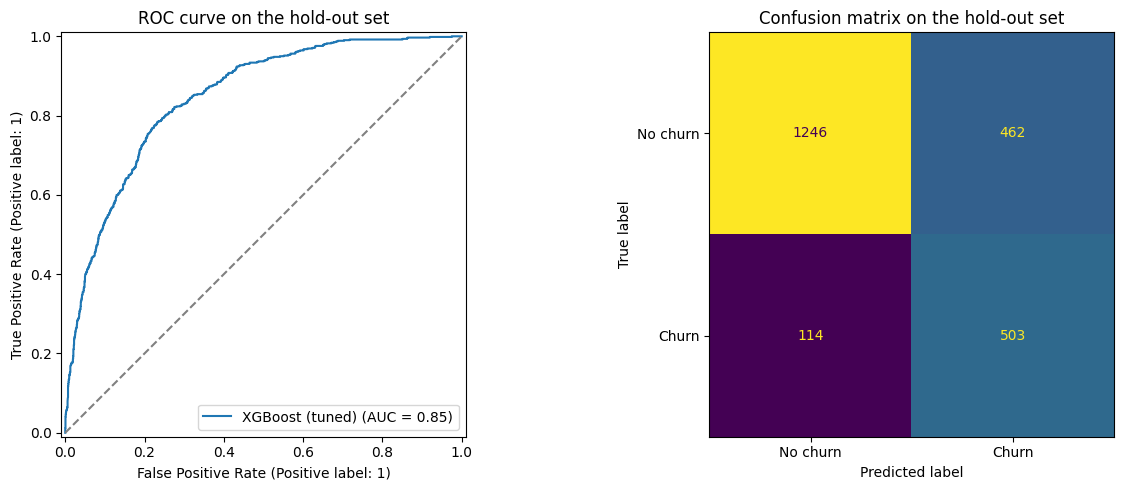

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
RocCurveDisplay.from_predictions(y_test, y_score, name=best_name, ax=axes[0])
axes[0].plot([0, 1], [0, 1], linestyle='--', color='grey')
axes[0].set_title('ROC curve on the hold-out set')

ConfusionMatrixDisplay.from_predictions(y_test, y_pred, display_labels=['No churn', 'Churn'],
                                        colorbar=False, ax=axes[1])
axes[1].set_title('Confusion matrix on the hold-out set')
plt.tight_layout()
plt.show()

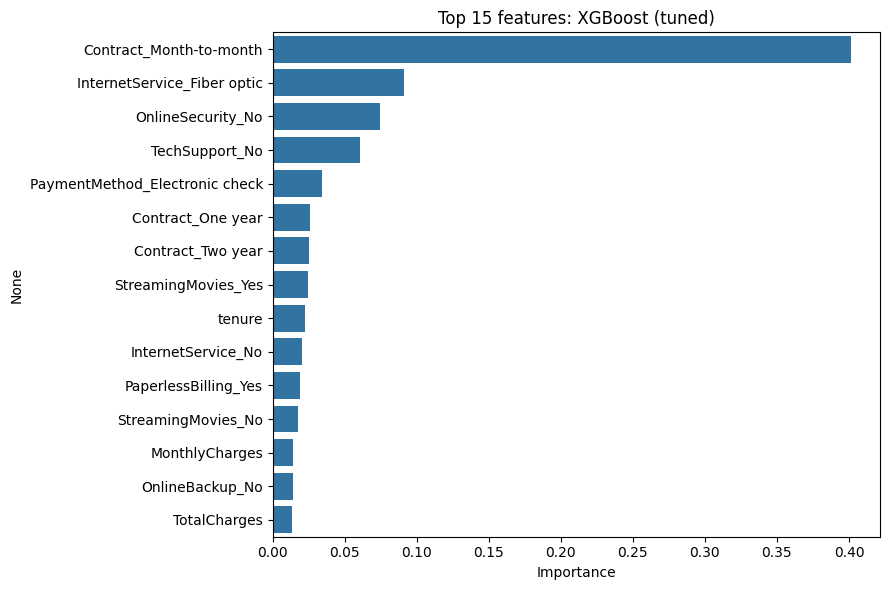

In [20]:
estimator = final_model.named_steps['model']
if hasattr(estimator, 'feature_importances_'):
    importance = estimator.feature_importances_
else:
    importance = np.abs(estimator.coef_[0])

feature_names = final_model.named_steps['prep'].get_feature_names_out()
top = (pd.Series(importance, index=[n.split('__', 1)[1] for n in feature_names])
       .sort_values(ascending=False).head(15))

plt.figure(figsize=(9, 6))
sns.barplot(x=top.values, y=top.index)
plt.title(f'Top 15 features: {best_name}')
plt.xlabel('Importance')
plt.tight_layout()
plt.show()